## 1. Imports and Data Loading

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import pymc as pm
import arviz as az
from sklearn.preprocessing import StandardScaler

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 200)

import warnings
warnings.filterwarnings('ignore')

# ── 1. Load the Data ─────────────────────────────────────────
games = pd.read_csv('DAC/data/games.csv')
pbp = pd.read_parquet('DAC/data/pbp.parquet')
player_games = pd.read_csv('DAC/data/player_games.csv')
tracking = pd.read_parquet('DAC/data/tracking.parquet')

### Define constants and helpers

In [2]:
LAMBDA             = 0.5
TARGET_DECAY_SHARE = 1/3

NON_SHOOTING_ZONES = {
    'centerPointDZ', 'eastPointDZ', 'westPointDZ',
    'eastOuterSlotDZ', 'westOuterSlotDZ', 'innerSlotDZ',
    'outsideNorthEastDZ', 'outsideNorthWestDZ',
    'northWestBoardsNZ', 'northEastBoardsNZ',
    'southWestBoardsNZ', 'southEastBoardsNZ',
    'southCenterNZ'
}

SO_PS_NAMES = {
    'socarry', 'soshot', 'sogoal', 'solpr',
    'pscarry', 'pslpr', 'pspuckprotection', 'penaltyshot'
}

### Set up player identification (team + jersey) and clean PBP

In [3]:
player_games['team_jersey'] = (
    player_games['team_id'].astype(str)
    + '_'
    + player_games['jersey_number'].astype(str)
)

pbp = pbp[~pbp['name'].isin(SO_PS_NAMES)].copy()
pbp = pbp.sort_values(['game_id', 'period', 'game_time']).reset_index(drop=True)

## 2. Set up Possessions

In [4]:
def _new_possession(df):
    """
    A new possession begins when:
      1. The game changes
      2. The period changes
      3. team_in_possession changes (including NaN transitions)
      4. The previous row was the last play of a possession
         — handles same-team breaks (scrambles, faceoff wins, etc.)
    """
    game_break   = df['game_id'] != df['game_id'].shift(1)
    period_break = df['period']  != df['period'].shift(1)

    curr      = df['team_in_possession']
    prev      = curr.shift(1)
    team_flip = (
        (curr.isna() != prev.isna())
        | (curr.notna() & prev.notna() & (curr != prev))
    )

    prev_ended = (
        df['is_last_play_of_possession']
        .shift(1)
        .fillna(False)
        .infer_objects(copy=False)
    )

    return game_break | period_break | team_flip | prev_ended


pbp['possession_id'] = _new_possession(pbp).cumsum()

# ── Sanity checks ─────────────────────────────────────────────────────────────
poss_lengths = (
    pbp[pbp['is_possession_event']]
    .groupby('possession_id')
    .size()
)

last_flags  = pbp[pbp['is_last_play_of_possession']]
actual_last = (
    pbp[pbp['is_possession_event']]
    .groupby('possession_id')
    .tail(1)
)
flag_match = last_flags['possession_id'].isin(actual_last['possession_id']).mean()

print("Possession-event counts per possession:")
print(poss_lengths.describe().round(2))
print(f"\nFlag match rate: {flag_match:.3f}  (expect 1.000)")

Possession-event counts per possession:
count    10212.00
mean         4.28
std          3.19
min          1.00
25%          2.00
50%          4.00
75%          6.00
max         32.00
dtype: float64

Flag match rate: 1.000  (expect 1.000)


## 3. Set up xG Proxy by Zone (Bayesian submodel to account for sample size differences)

In [5]:
shot_poss = pbp[pbp['name'] == 'shot'][['possession_id', 'play_section']].copy()
shot_poss['converted'] = shot_poss['possession_id'].isin(
    pbp[pbp['name'] == 'goal']['possession_id']
)

zone_conversion = (
    shot_poss
    .groupby('play_section')['converted']
    .agg(['sum', 'count'])
    .rename(columns={'sum': 'goals', 'count': 'shots'})
)

zone_conv_shooting = zone_conversion[
    ~zone_conversion.index.isin(NON_SHOOTING_ZONES)
].copy()

zones_s   = zone_conv_shooting.index.tolist()
goals_s   = zone_conv_shooting['goals'].values.astype(int)
shots_s   = zone_conv_shooting['shots'].values.astype(int)

with pm.Model() as xg_model:
    mu    = pm.Beta('mu', alpha=2, beta=16)
    kappa = pm.HalfNormal('kappa', sigma=20)

    alpha_z = mu * kappa
    beta_z  = (1 - mu) * kappa
    theta   = pm.Beta('theta', alpha=alpha_z, beta=beta_z, shape=len(zones_s))

    _ = pm.Binomial('goals', n=shots_s, p=theta, observed=goals_s)

    trace = pm.sample(
        2000, tune=1000, target_accept=0.9,
        random_seed=42, progressbar=True
    )

theta_post = az.summary(trace, var_names=['theta'])['mean'].values

xg_bayes = pd.DataFrame({
    'play_section' : zones_s,
    'goals'        : goals_s,
    'shots'        : shots_s,
    'xg_raw'       : goals_s / shots_s.clip(1),
    'xg_bayes'     : theta_post
}).set_index('play_section')

xg_nonshooting = pd.DataFrame({
    'play_section' : list(NON_SHOOTING_ZONES),
    'xg_bayes'     : 0.0
}).set_index('play_section')

xg_bayes_final = pd.concat([xg_bayes[['xg_bayes']], xg_nonshooting])

print("Zone xG proxy (shooting zones):")
print(xg_bayes.sort_values('xg_bayes', ascending=False).round(4))

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [mu, kappa, theta]


Output()

Sampling 4 chains for 1_000 tune and 2_000 draw iterations (4_000 + 8_000 draws total) took 28 seconds.


Zone xG proxy (shooting zones):
                  goals  shots  xg_raw  xg_bayes
play_section                                    
innerSlot            52    343  0.1516     0.148
eastOuterSlot        23    269  0.0855     0.084
westOuterSlot        21    286  0.0734     0.073
northCenterNZ         1     14  0.0714     0.066
outsideNorthEast      9    200  0.0450     0.046
outsideNorthWest      7    182  0.0385     0.040
centerPoint           3    312  0.0096     0.012
westPoint             1    169  0.0059     0.010
eastPoint             0    195  0.0000     0.004


## 4. Set up LOOCV for xT Grid

In [6]:
game_ids  = pbp['game_id'].unique()
all_av_dfs = []

print(f"Running LOOCV over {len(game_ids)} games...")

for test_game in game_ids:

    # ── Training data: all games except test_game ─────────────────────────────
    train_pbp = pbp[pbp['game_id'] != test_game].copy()
    train_pbp['possession_id'] = _new_possession(train_pbp).cumsum()

    # Terminal values on training possessions
    train_has_goal = (
        train_pbp[train_pbp['name'] == 'goal']
        .groupby('possession_id').size().gt(0).rename('has_goal')
    )
    train_has_shot = (
        train_pbp[train_pbp['name'] == 'shot']
        .groupby('possession_id').size().gt(0).rename('has_shot')
    )
    train_shot_xg = (
        train_pbp[train_pbp['name'] == 'shot']
        [['possession_id', 'play_section']].copy()
    )
    train_shot_xg['xg_bayes'] = (
        train_shot_xg['play_section']
        .map(xg_bayes_final['xg_bayes'])
        .fillna(0.0)
    )
    train_best_shot_xg = (
        train_shot_xg.groupby('possession_id')['xg_bayes']
        .max().rename('best_shot_xg')
    )
    train_terminal = (
        pd.DataFrame(index=train_pbp['possession_id'].unique())
        .join(train_has_goal)
        .join(train_has_shot)
        .join(train_best_shot_xg)
    )
    train_terminal['has_goal']     = train_terminal['has_goal'].fillna(False).astype(bool)
    train_terminal['has_shot']     = train_terminal['has_shot'].fillna(False).astype(bool)
    train_terminal['best_shot_xg'] = train_terminal['best_shot_xg'].fillna(0.0)
    train_terminal['terminal_value'] = np.where(
        train_terminal['has_goal'], 1.0,
        np.where(train_terminal['has_shot'], train_terminal['best_shot_xg'], 0.0)
    )

    # xT grid from training data only
    train_poss_events = train_pbp[train_pbp['is_possession_event']].copy()
    train_poss_events = train_poss_events.merge(
        train_terminal[['terminal_value']],
        left_on='possession_id', right_index=True, how='left'
    )
    xt_grid_train = (
        train_poss_events
        .groupby('play_section')['terminal_value']
        .mean()
        .clip(lower=0.0)
        .rename('xt_value')
    )

    # ── Test data: held-out game ───────────────────────────────────────────────
    test_pbp = pbp[pbp['game_id'] == test_game].copy()
    test_pbp['possession_id'] = _new_possession(test_pbp).cumsum()

    # Terminal values on test possessions
    test_has_goal = (
        test_pbp[test_pbp['name'] == 'goal']
        .groupby('possession_id').size().gt(0).rename('has_goal')
    )
    test_has_shot = (
        test_pbp[test_pbp['name'] == 'shot']
        .groupby('possession_id').size().gt(0).rename('has_shot')
    )
    test_shot_xg = (
        test_pbp[test_pbp['name'] == 'shot']
        [['possession_id', 'play_section']].copy()
    )
    test_shot_xg['xg_bayes'] = (
        test_shot_xg['play_section']
        .map(xg_bayes_final['xg_bayes'])
        .fillna(0.0)
    )
    test_best_shot_xg = (
        test_shot_xg.groupby('possession_id')['xg_bayes']
        .max().rename('best_shot_xg')
    )
    test_terminal = (
        pd.DataFrame(index=test_pbp['possession_id'].unique())
        .join(test_has_goal)
        .join(test_has_shot)
        .join(test_best_shot_xg)
    )
    test_terminal['has_goal']     = test_terminal['has_goal'].fillna(False).astype(bool)
    test_terminal['has_shot']     = test_terminal['has_shot'].fillna(False).astype(bool)
    test_terminal['best_shot_xg'] = test_terminal['best_shot_xg'].fillna(0.0)
    test_terminal['terminal_value'] = np.where(
        test_terminal['has_goal'], 1.0,
        np.where(test_terminal['has_shot'], test_terminal['best_shot_xg'], 0.0)
    )

    # Score test possession events using training xT grid
    test_poss = test_pbp[test_pbp['is_possession_event']].copy()
    test_poss['xt_current'] = (
        test_poss['play_section']
        .map(xt_grid_train)
        .fillna(0.0)
    )
    test_poss['terminal_value'] = (
        test_poss['possession_id']
        .map(test_terminal['terminal_value'])
        .fillna(0.0)
    )
    test_poss = test_poss.sort_values(['possession_id', 'game_time']).reset_index(drop=True)

    test_poss['xt_next'] = test_poss.groupby('possession_id')['xt_current'].shift(-1)
    test_poss['xt_next'] = np.where(
        test_poss['is_last_play_of_possession'],
        test_poss['terminal_value'],
        test_poss['xt_next']
    ).astype(float)
    test_poss['xt_next'] = test_poss['xt_next'].fillna(0.0)

    test_poss['av_base'] = test_poss['xt_next'] - test_poss['xt_current']

    test_poss['event_rank'] = test_poss.groupby('possession_id').cumcount()
    test_poss['poss_length'] = (
        test_poss.groupby('possession_id')['event_rank'].transform('max')
    )
    test_poss['k'] = test_poss['poss_length'] - test_poss['event_rank']

    # Store raw_decay for post-loop alpha calibration (av_decay filled later)
    test_poss['raw_decay'] = np.where(
        test_poss['k'] > 0,
        (LAMBDA ** test_poss['k']) * test_poss['terminal_value'],
        0.0
    )

    all_av_dfs.append(test_poss[[
        'game_id', 'period', 'game_time', 'possession_id',
        'player_id', 'name', 'outcome', 'event_team',
        'play_section', 'zone', 'is_last_play_of_possession',
        'terminal_value', 'av_base', 'raw_decay', 'k'
    ]])

av_df = pd.concat(all_av_dfs, ignore_index=True)

# ── Post-loop alpha calibration on assembled LOOCV output ────────────────────
mean_abs_base  = av_df['av_base'].abs().mean()
mean_abs_decay = av_df['raw_decay'].abs().mean()
ALPHA = (
    TARGET_DECAY_SHARE * mean_abs_base
    / ((1 - TARGET_DECAY_SHARE) * mean_abs_decay)
)

av_df['av_decay'] = np.where(
    av_df['k'] > 0,
    ALPHA * (LAMBDA ** av_df['k']) * av_df['terminal_value'],
    0.0
)
av_df['av_total'] = av_df['av_base'] + av_df['av_decay']

# Verify achieved split
total_abs    = av_df['av_base'].abs().mean() + av_df['av_decay'].abs().mean()
base_share   = av_df['av_base'].abs().mean()  / total_abs
decay_share  = av_df['av_decay'].abs().mean() / total_abs

print(f"Alpha: {ALPHA:.4f}")
print(f"Base share:  {base_share:.1%}  (target 66.7%)")
print(f"Decay share: {decay_share:.1%}  (target 33.3%)")
print(f"\nTotal LOOCV events: {len(av_df):,}")

print("\nMean av_total by event type:")
print(
    av_df.groupby('name')['av_total']
    .agg(['mean', 'count'])
    .sort_values('mean', ascending=False)
    .round(5)
)

Running LOOCV over 19 games...
Alpha: 1.8506
Base share:  66.7%  (target 66.7%)
Decay share: 33.3%  (target 33.3%)

Total LOOCV events: 43,691

Mean av_total by event type:
                   mean  count
name                          
goal            0.82216    119
carry           0.01626   3850
reception       0.01351   9870
lpr             0.00667   9873
pass           -0.00123  13290
shot           -0.00387   2009
dumpout        -0.00901   1166
dumpin         -0.01570    997
puckprotection -0.02151   2517


## 5. Player Value Aggregation (RAW)

In [7]:
player_info = (
    player_games[['player_id', 'first_name', 'last_name', 'team_id', 'position']]
    .drop_duplicates(subset='player_id')
    .assign(player_name=lambda d: d['first_name'] + ' ' + d['last_name'])
)

team_names = pd.concat([
    games[['home_team_id', 'home_team_short']].rename(
        columns={'home_team_id': 'team_id', 'home_team_short': 'team_short'}),
    games[['away_team_id', 'away_team_short']].rename(
        columns={'away_team_id': 'team_id', 'away_team_short': 'team_short'})
]).drop_duplicates(subset='team_id')

av_attributed = av_df[av_df['player_id'].notna()].copy()
av_attributed['player_id'] = av_attributed['player_id'].astype(int)

player_raw = (
    av_attributed
    .groupby('player_id')
    .agg(
        n_events      = ('av_total', 'count'),
        av_total_sum  = ('av_total', 'sum'),
        av_total_mean = ('av_total', 'mean'),
        av_base_mean  = ('av_base',  'mean'),
        av_decay_mean = ('av_decay', 'mean'),
    )
    .reset_index()
    .merge(player_info, on='player_id', how='left')
    .merge(team_names,  on='team_id',   how='left')
)

print(f"Players with attributed events: {len(player_raw)}")
print(f"\nEvent count distribution:")
print(player_raw['n_events'].describe().round(1))

Players with attributed events: 188

Event count distribution:
count    188.0
mean     232.4
std      145.8
min        4.0
25%      130.2
50%      217.0
75%      318.0
max      719.0
Name: n_events, dtype: float64


## 6. Bayesian Hierarchical Shrinkage

In [8]:
player_ids = player_raw['player_id'].values
id_to_idx  = {pid: i for i, pid in enumerate(player_ids)}
n_players  = len(player_ids)

av_attributed['player_idx'] = av_attributed['player_id'].map(id_to_idx)
av_clean = av_attributed[av_attributed['player_idx'].notna()].copy()
av_clean['player_idx'] = av_clean['player_idx'].astype(int)

obs_av  = av_clean['av_total'].values
obs_idx = av_clean['player_idx'].values

with pm.Model() as player_model:
    mu_pop    = pm.Normal('mu_pop',    mu=0.0,  sigma=0.05)
    sigma_pop = pm.HalfNormal('sigma_pop',       sigma=0.05)
    mu_p      = pm.Normal('mu_p', mu=mu_pop, sigma=sigma_pop, shape=n_players)
    sigma_obs = pm.HalfNormal('sigma_obs',       sigma=0.15)

    _ = pm.Normal('av_obs', mu=mu_p[obs_idx], sigma=sigma_obs, observed=obs_av)

    trace_players = pm.sample(
        2000, tune=1000, target_accept=0.9,
        random_seed=42, progressbar=True
    )

summary = az.summary(trace_players, var_names=['mu_p'])

player_raw['av_shrunk_mean'] = summary['mean'].values
player_raw['av_shrunk_sd']   = summary['sd'].values
player_raw['av_shrunk_lo']   = summary['hdi_3%'].values
player_raw['av_shrunk_hi']   = summary['hdi_97%'].values

pop_mean = player_raw['av_shrunk_mean'].mean()
player_raw['av_centered']    = player_raw['av_shrunk_mean'] - pop_mean
player_raw['av_centered_lo'] = player_raw['av_shrunk_lo']   - pop_mean
player_raw['av_centered_hi'] = player_raw['av_shrunk_hi']   - pop_mean

player_raw['credibly_above_avg'] = player_raw['av_centered_lo'] > 0
player_raw['credibly_below_avg'] = player_raw['av_centered_hi'] < 0

results = (
    player_raw[player_raw['player_name'].notna()]
    .sort_values('av_centered', ascending=False)
    .reset_index(drop=True)
)

print(f"Population mean: {pop_mean:.5f}")
print(f"Credibly above average: {results['credibly_above_avg'].sum()}")
print(f"Credibly below average: {results['credibly_below_avg'].sum()}")

print("\nTop 15:")
print(results[[
    'player_name', 'team_short', 'position', 'n_events',
    'av_centered', 'av_centered_lo', 'av_centered_hi'
]].head(15).round(4).to_string(index=False))

print("\nBottom 15:")
print(results[[
    'player_name', 'team_short', 'position', 'n_events',
    'av_centered', 'av_centered_lo', 'av_centered_hi'
]].tail(15).round(4).to_string(index=False))

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [mu_pop, sigma_pop, mu_p, sigma_obs]


Output()

Sampling 4 chains for 1_000 tune and 2_000 draw iterations (4_000 + 8_000 draws total) took 73 seconds.


Population mean: 0.00464
Credibly above average: 18
Credibly below average: 0

Top 15:
     player_name team_short position  n_events  av_centered  av_centered_lo  av_centered_hi
Elton Hermansson        SWE        F       534       0.0234          0.0174          0.0304
 Blake Zielinski        USA        F       401       0.0154          0.0084          0.0224
 Marcus Nordmark        SWE        F       449       0.0144          0.0084          0.0214
Simon Belohorsky        CZE        F       166       0.0134          0.0054          0.0224
     Levi Harper        USA        D       437       0.0134          0.0064          0.0194
  Oliver Ozogány        SVK        F       341       0.0134          0.0064          0.0204
  Ethan Belchetz        CAN        F       359       0.0124          0.0054          0.0194
  Mathis Preston        CAN        F       481       0.0114          0.0054          0.0184
  Niclas Rentsch        SUI        F       177       0.0114          0.0024          

## 7. Quick Validation

Correlation — team AV vs. goals scored: 0.973
Correlation — AV differential vs. goal differential: 0.977


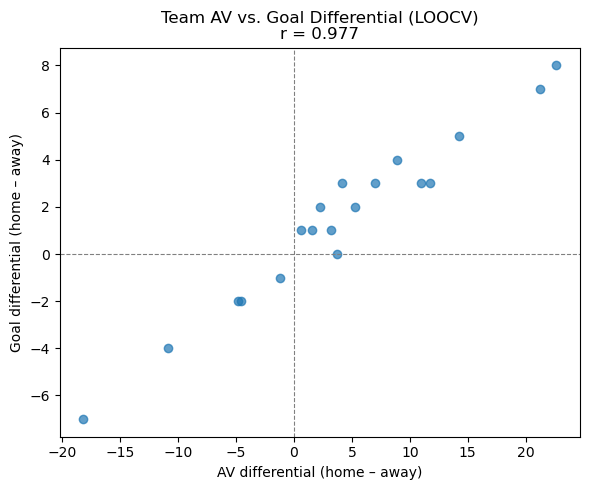

In [9]:
# ── Team AV vs. goals and goal differential ───────────────────────────────────
#
# NOTE: these correlations are structurally inflated because goals are a direct
# input to terminal values. They confirm internal consistency, not predictive
# validity. The AV differential vs. goal differential check (game level) is
# the more meaningful of the two — one step further removed from the goal input.

player_team_map = (
    player_games[['game_id', 'player_id', 'team_id']]
    .drop_duplicates()
    .assign(player_id=lambda d: d['player_id'].astype(int))
)

av_df_clean = av_df[av_df['player_id'].notna()].copy()
av_df_clean['player_id'] = av_df_clean['player_id'].astype(int)

av_with_team = (
    av_df_clean
    .merge(player_team_map, on=['game_id', 'player_id'], how='left')
    .dropna(subset=['team_id'])
    .assign(team_id=lambda d: d['team_id'].astype(int))
)

team_av = (
    av_with_team
    .groupby(['game_id', 'team_id'])['av_total']
    .sum()
    .reset_index()
    .rename(columns={'av_total': 'team_av'})
)

# ── Goal attribution via rsplit-normalized team name join ─────────────────────
goal_events = pbp[
    (pbp['name'] == 'goal') & (pbp['is_possession_event'])
].copy()
goal_events['event_team_clean'] = (
    goal_events['event_team']
    .str.rsplit(' ', n=1)
    .str[-1]
)

team_name_to_id = pd.concat([
    games[['home_team_id', 'home_team_name']].rename(
        columns={'home_team_id': 'team_id', 'home_team_name': 'team_name'}),
    games[['away_team_id', 'away_team_name']].rename(
        columns={'away_team_id': 'team_id', 'away_team_name': 'team_name'})
]).drop_duplicates()
team_name_to_id['team_name_clean'] = (
    team_name_to_id['team_name']
    .str.rsplit(' ', n=1)
    .str[-1]
)

goal_events = goal_events.merge(
    team_name_to_id[['team_id', 'team_name_clean']],
    left_on='event_team_clean', right_on='team_name_clean',
    how='left'
)

goals_per_team = (
    goal_events
    .groupby(['game_id', 'team_id'])
    .size()
    .reset_index(name='goals')
)

# ── Correlations and plot (unchanged) ─────────────────────────────────────────
team_perf = team_av.merge(goals_per_team, on=['game_id', 'team_id'], how='left').fillna(0)
corr_av_goals = team_perf['team_av'].corr(team_perf['goals'])
print(f"Correlation — team AV vs. goals scored: {corr_av_goals:.3f}")

game_info = games[['game_id', 'home_team_id', 'away_team_id']].copy()

home_goals = (
    goals_per_team
    .merge(game_info[['game_id', 'home_team_id']].rename(
        columns={'home_team_id': 'team_id'}), on=['game_id', 'team_id'])
    [['game_id', 'goals']].rename(columns={'goals': 'home_goals'})
)
away_goals = (
    goals_per_team
    .merge(game_info[['game_id', 'away_team_id']].rename(
        columns={'away_team_id': 'team_id'}), on=['game_id', 'team_id'])
    [['game_id', 'goals']].rename(columns={'goals': 'away_goals'})
)

home_av = (
    team_av
    .merge(game_info[['game_id', 'home_team_id']].rename(
        columns={'home_team_id': 'team_id'}), on=['game_id', 'team_id'])
    [['game_id', 'team_av']].rename(columns={'team_av': 'home_av'})
)
away_av = (
    team_av
    .merge(game_info[['game_id', 'away_team_id']].rename(
        columns={'away_team_id': 'team_id'}), on=['game_id', 'team_id'])
    [['game_id', 'team_av']].rename(columns={'team_av': 'away_av'})
)

game_perf = (
    game_info
    .merge(home_goals, on='game_id', how='left')
    .merge(away_goals, on='game_id', how='left')
    .merge(home_av,    on='game_id', how='left')
    .merge(away_av,    on='game_id', how='left')
    .fillna(0)
)
game_perf['goal_diff'] = game_perf['home_goals'] - game_perf['away_goals']
game_perf['av_diff']   = game_perf['home_av']    - game_perf['away_av']

corr_diff = game_perf['av_diff'].corr(game_perf['goal_diff'])
print(f"Correlation — AV differential vs. goal differential: {corr_diff:.3f}")

fig, ax = plt.subplots(figsize=(6, 5))
ax.scatter(game_perf['av_diff'], game_perf['goal_diff'], alpha=0.7)
ax.axhline(0, color='gray', linestyle='--', linewidth=0.8)
ax.axvline(0, color='gray', linestyle='--', linewidth=0.8)
ax.set_xlabel('AV differential (home – away)')
ax.set_ylabel('Goal differential (home – away)')
ax.set_title(f'Team AV vs. Goal Differential (LOOCV)\nr = {corr_diff:.3f}')
plt.tight_layout()
plt.savefig('figures/validation_av_vs_goal_diff.png', dpi=150)
plt.show()

## 8. Figures

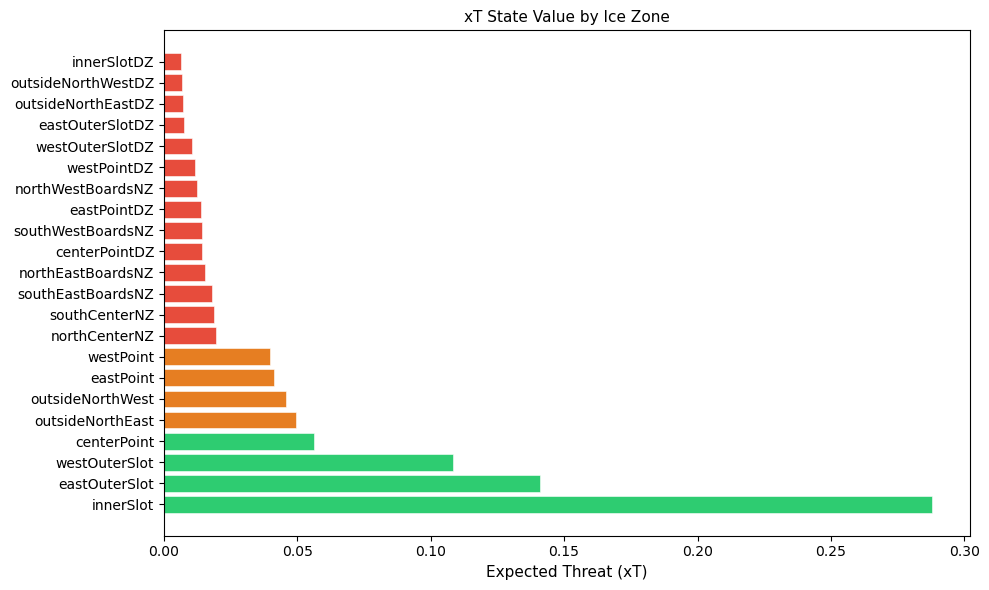

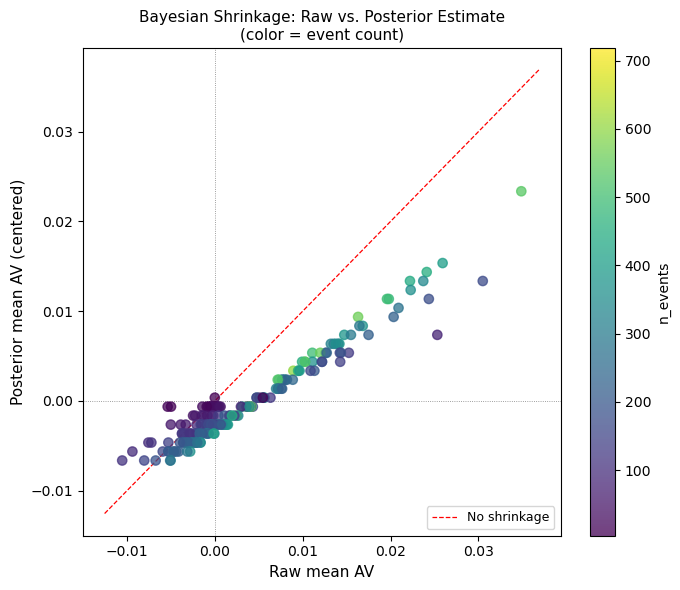

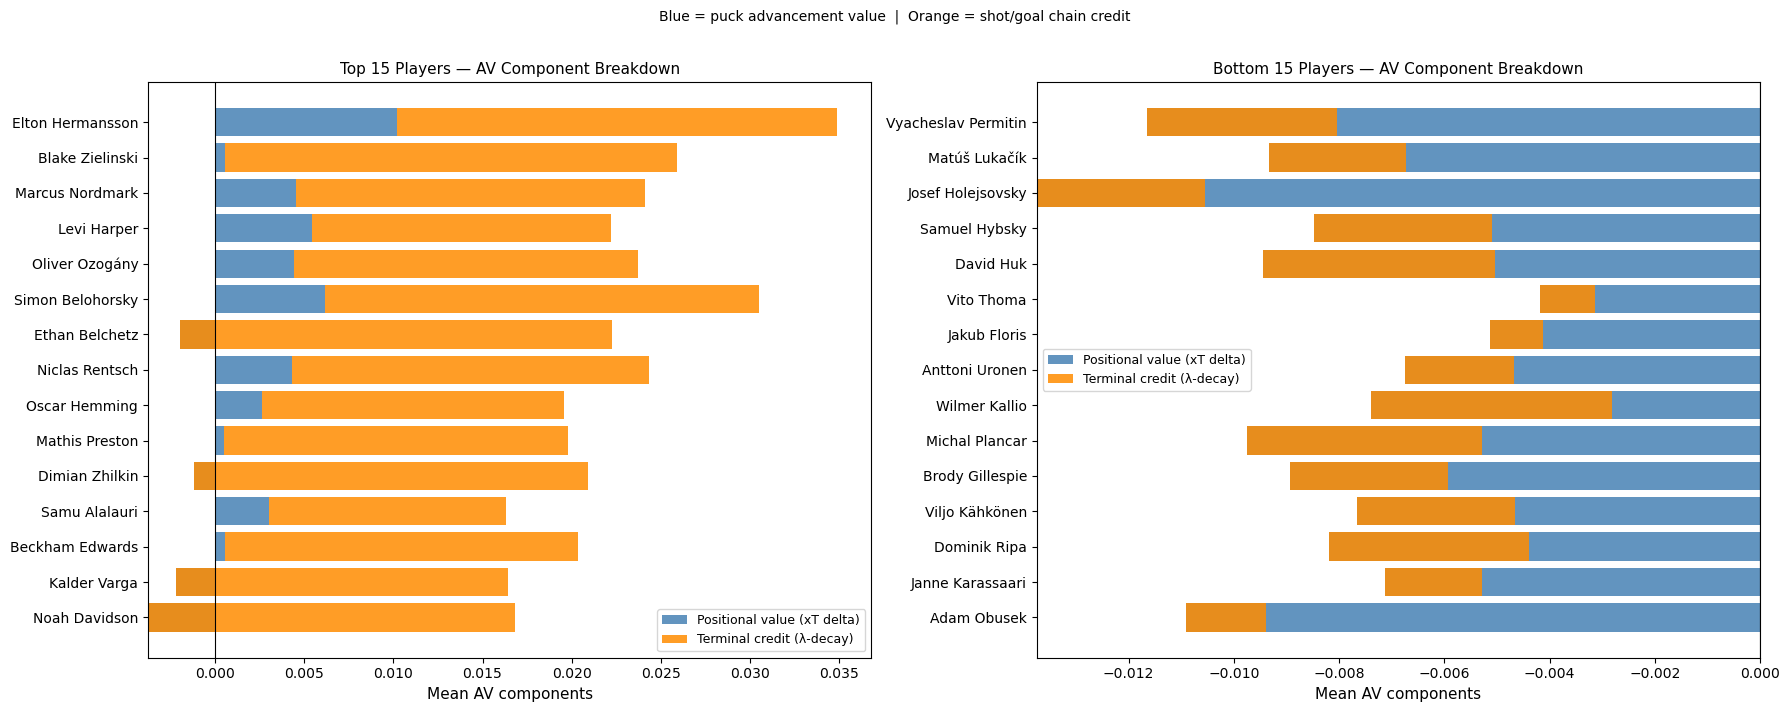

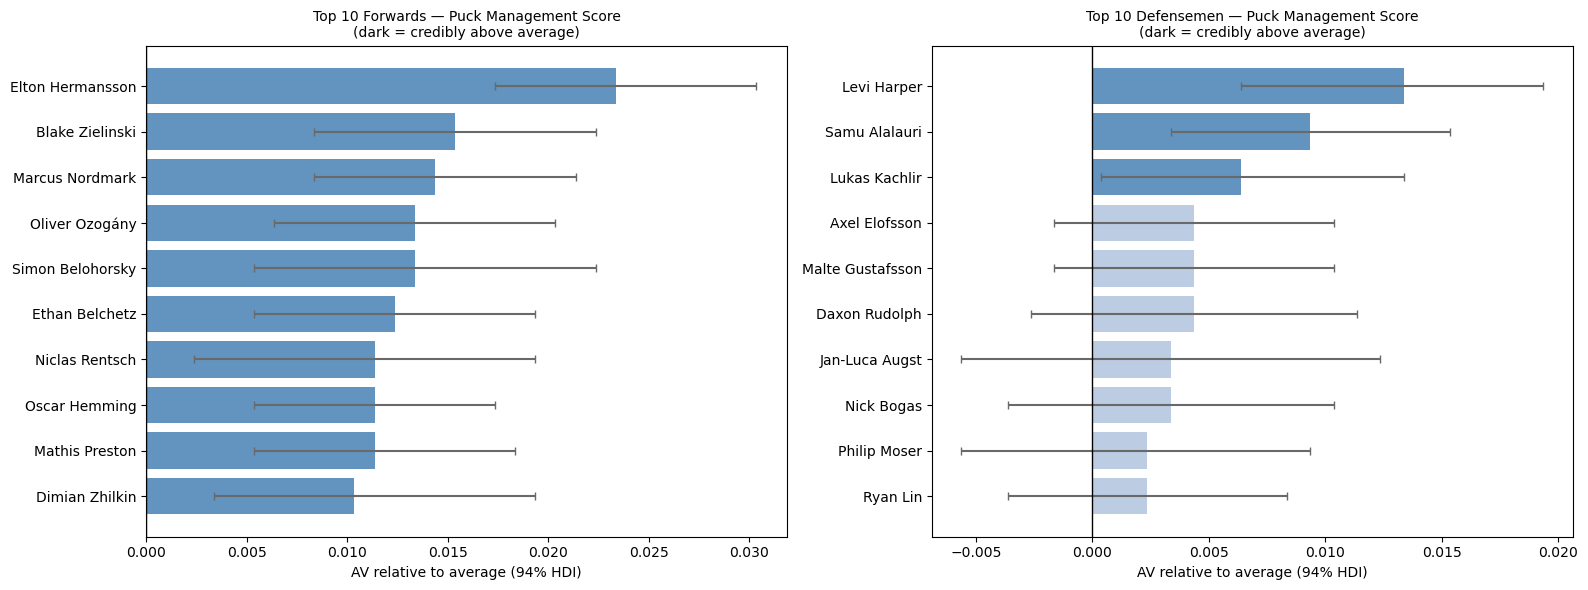

In [10]:
import os
os.makedirs('figures', exist_ok=True)

# ── Figure 1: xT grid ─────────────────────────────────────────────────────────
# Use the full-data xT grid for display (LOOCV grids are for scoring only)
poss_events_full = pbp[pbp['is_possession_event']].copy()
poss_has_goal_full = (
    pbp[pbp['name'] == 'goal']
    .groupby('possession_id').size().gt(0).rename('has_goal')
)
poss_has_shot_full = (
    pbp[pbp['name'] == 'shot']
    .groupby('possession_id').size().gt(0).rename('has_shot')
)
shot_xg_full = pbp[pbp['name'] == 'shot'][['possession_id', 'play_section']].copy()
shot_xg_full['xg_bayes'] = (
    shot_xg_full['play_section'].map(xg_bayes_final['xg_bayes']).fillna(0.0)
)
best_shot_xg_full = (
    shot_xg_full.groupby('possession_id')['xg_bayes'].max().rename('best_shot_xg')
)
poss_terminal_full = (
    pd.DataFrame(index=pbp['possession_id'].unique())
    .join(poss_has_goal_full)
    .join(poss_has_shot_full)
    .join(best_shot_xg_full)
)
poss_terminal_full['has_goal']     = poss_terminal_full['has_goal'].fillna(False).astype(bool)
poss_terminal_full['has_shot']     = poss_terminal_full['has_shot'].fillna(False).astype(bool)
poss_terminal_full['best_shot_xg'] = poss_terminal_full['best_shot_xg'].fillna(0.0)
poss_terminal_full['terminal_value'] = np.where(
    poss_terminal_full['has_goal'], 1.0,
    np.where(poss_terminal_full['has_shot'], poss_terminal_full['best_shot_xg'], 0.0)
)
poss_events_full = poss_events_full.merge(
    poss_terminal_full[['terminal_value']],
    left_on='possession_id', right_index=True, how='left'
)
xt_grid_display = (
    poss_events_full
    .groupby('play_section')['terminal_value']
    .mean()
    .clip(lower=0.0)
    .rename('xt_value')
    .sort_values(ascending=False)
)

fig, ax = plt.subplots(figsize=(10, 6))
colors = [
    '#2ecc71' if v > 0.05
    else '#e67e22' if v > 0.02
    else '#e74c3c'
    for v in xt_grid_display
]
ax.barh(xt_grid_display.index, xt_grid_display.values,
        color=colors, edgecolor='white', linewidth=0.4)
ax.set_xlabel('Expected Threat (xT)', fontsize=11)
ax.set_title('xT State Value by Ice Zone', fontsize=11)
plt.tight_layout()
plt.savefig('figures/fig1_xt_grid.png', dpi=150)
plt.show()

# ── Figure 2: Shrinkage diagnostic ───────────────────────────────────────────
fig, ax = plt.subplots(figsize=(7, 6))
sc = ax.scatter(
    results['av_total_mean'],
    results['av_centered'],
    c=results['n_events'],
    cmap='viridis', alpha=0.75, s=45, zorder=3
)
lims = [
    min(results['av_total_mean'].min(), results['av_centered'].min()) - 0.002,
    max(results['av_total_mean'].max(), results['av_centered'].max()) + 0.002
]
ax.plot(lims, lims, 'r--', linewidth=0.9, label='No shrinkage', zorder=2)
ax.axhline(0, color='gray', linewidth=0.6, linestyle=':')
ax.axvline(0, color='gray', linewidth=0.6, linestyle=':')
ax.set_xlabel('Raw mean AV', fontsize=11)
ax.set_ylabel('Posterior mean AV (centered)', fontsize=11)
ax.set_title('Bayesian Shrinkage: Raw vs. Posterior Estimate\n(color = event count)',
             fontsize=11)
ax.legend(fontsize=9)
plt.colorbar(sc, ax=ax, label='n_events')
plt.tight_layout()
plt.savefig('figures/fig2_shrinkage.png', dpi=150)
plt.show()

# ── Figure 3: AV component breakdown — top and bottom 15 ─────────────────────
fig, axes = plt.subplots(1, 2, figsize=(18, 7))

for ax, subset, title in [
    (axes[0], results.head(15).sort_values('av_centered'),
     'Top 15 Players'),
    (axes[1], results.tail(15).sort_values('av_centered', ascending=False),
     'Bottom 15 Players'),
]:
    ax.barh(
        subset['player_name'], subset['av_base_mean'],
        label='Positional value (xT delta)', color='steelblue', alpha=0.85
    )
    ax.barh(
        subset['player_name'], subset['av_decay_mean'],
        left=subset['av_base_mean'],
        label='Terminal credit (λ-decay)', color='darkorange', alpha=0.85
    )
    ax.axvline(0, color='black', linewidth=0.8)
    ax.set_xlabel('Mean AV components', fontsize=11)
    ax.set_title(f'{title} — AV Component Breakdown', fontsize=11)
    ax.legend(fontsize=9)

plt.suptitle(
    'Blue = puck advancement value  |  Orange = shot/goal chain credit',
    fontsize=10, y=1.01
)
plt.tight_layout()
plt.savefig('figures/fig3_components.png', dpi=150, bbox_inches='tight')
plt.show()

# ── Figure 4: Position-stratified top 10 ─────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

for ax, pos_group, label in [
    (axes[0], {'F', 'LW', 'RW', 'C'}, 'Forwards'),
    (axes[1], {'D'},                   'Defensemen'),
]:
    sub = (
        results[results['position'].isin(pos_group)]
        .head(10)
        .sort_values('av_centered')
    )
    colors = ['steelblue' if c else 'lightsteelblue'
              for c in sub['credibly_above_avg']]
    ax.barh(
        sub['player_name'], sub['av_centered'],
        xerr=[
            sub['av_centered'] - sub['av_centered_lo'],
            sub['av_centered_hi'] - sub['av_centered']
        ],
        color=colors, alpha=0.85, ecolor='dimgray', capsize=3
    )
    ax.axvline(0, color='black', linewidth=1.0)
    ax.set_xlabel('AV relative to average (94% HDI)', fontsize=10)
    ax.set_title(f'Top 10 {label} — Puck Management Score\n'
                 f'(dark = credibly above average)', fontsize=10)

plt.tight_layout()
plt.savefig('figures/fig4_by_position.png', dpi=150)
plt.show()